In [1]:
import numpy as np
import pandas as pd
import cv2 as cv
from google.colab.patches import cv2_imshow # for image display
from skimage import io
from skimage import transform
from PIL import Image
import matplotlib.pylab as plt

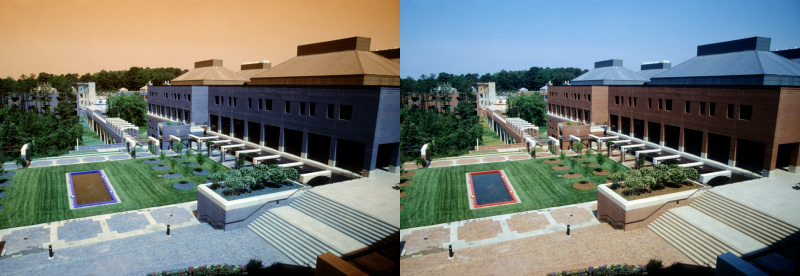

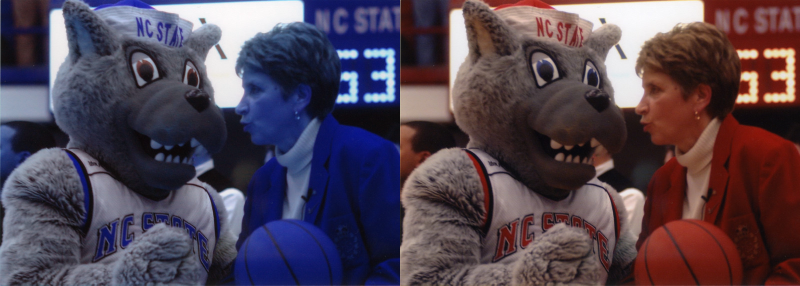

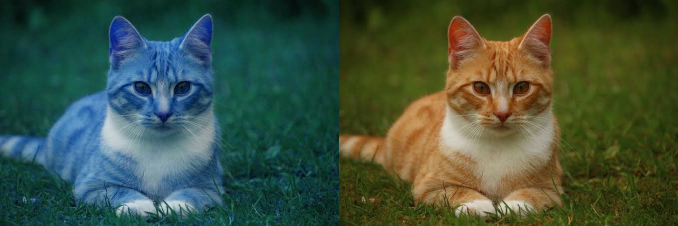

In [2]:
# Membuat list untuk menyimpan url dari beberapa image
urls = ["https://iiif.lib.ncsu.edu/iiif/0052574/full/800,/0/default.jpg",
        "https://iiif.lib.ncsu.edu/iiif/0016007/full/800,/0/default.jpg",
        "https://encrypted-tbn0.gstatic.com/images?q=tbn:ANd9GcR_3h4I13e4a47X2ysmga4lTex7EILxN6QxL-kqaSxVXxzZhVVNBhF41XU&s=10"]

# baca dan tampilkan image
# loop pada tiap url image, beberapa image dapat disimpan pada list
for url in urls:
  image = io.imread(url)                           #read image
  image = cv.resize(image, (0,0), fx=0.5, fy=0.5)  #resize image to half size
  image_2 = cv.cvtColor(image, cv.COLOR_BGR2RGB)   #convert color to RGB
  final_frame = cv.hconcat((image, image_2))       #concatenate image
  cv2_imshow(final_frame)                          #show image
  print('\n')

resolusi image: tinggi x lebar =  226  x  339


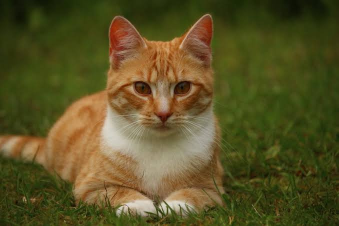

In [3]:
tinggi = image_2.shape[0]
lebar = image_2.shape[1]
print("resolusi image: tinggi x lebar = ", tinggi," x ", lebar)
cv2_imshow(image_2)

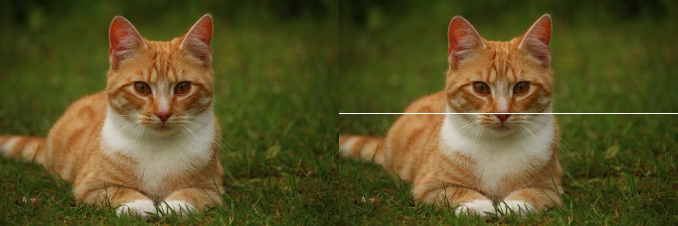

In [4]:
image_2 = cv.cvtColor(image, cv.COLOR_BGR2RGB)
image_3 = cv.cvtColor(image, cv.COLOR_BGR2RGB)

#membuat garis horizontal ditengah image
for y in range (lebar):
  image_3[int((tinggi)/2),y] = [255,255,255]

final_frame = cv.hconcat((image_2, image_3))
cv2_imshow(final_frame)

**PERTANYAAN PRAKTIKUM D2**

1. Jelaskan, mengapa pada modul praktikum ini eksekusi kode Python dilakukan
menggunakan Google Colab? <br>
**Jawab** : Sangat praktis karena kita tidak perlu menginstal environment atau library (seperti OpenCV) di perangkat lokal. Selain itu, beban komputasi ditanggung oleh server Google sehingga lebih ringan untuk laptop mahasiswa.
2. Jelaskan mengenai kegunaan setiap library pada praktikum langkah ke
delapan? Apakah semua library tersebut harus digunakan dalam praktikum
sesi ini? <br>
**Jawab** :
*   numpy & pandas: Manipulasi data
*   cv2 & cv2_imshow: Pemrosesan dan penampilan citra digital.
*   skimage & PIL: Membaca, mengolah, dan menyimpan file gambar.
*   matplotlib: Visualisasi data atau grafik.
*   Tidak semua wajib digunakan. Pada sesi ini kita hanya butuh skimage.io (untuk membaca dari URL internet), cv2, dan cv2_imshow
3. Pada uji coba langkah ke-9 terdapat potongan kode program sebagai berikut : 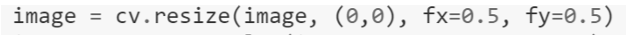<br>
Apa kegunaan kode program tersebut?dan apa pengaruhnya jika tidak
dilakukan? <br>
**Jawab** :
**Kode** cv.resize: Berfungsi memperkecil gambar menjadi 50% dari ukuran aslinya. Jika diabaikan, gambar akan diproses dan ditampilkan dalam resolusi aslinya, yang berpotensi memakan ruang layar berlebih dan memberatkan RAM saat proses penggabungan.
4. Perhatikan potongan kode progam berikut :
Apakah kegunaan kode [255,255,255] ? Jelaskan!
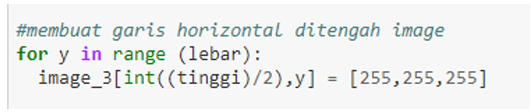<br> **Jawab** : **Kode** [255, 255, 255]: Merepresentasikan kombinasi nilai maksimal dari RGB (Red, Green, Blue) yang menghasilkan warna putih. Pada kode tersebut, nilai ini ditugaskan pada koordinat tertentu untuk menggambar garis horizontal putih di tengah citra.


5. Jelaskan keterkaitan antara pixel dan juga resolusi gambar yang tinggi ataupun
rendah! <br> **Jawab** : **Keterkaitan pixel dan resolusi** : Berbanding lurus. Resolusi **tinggi** berarti sebuah gambar tersusun dari jumlah pixel yang sangat banyak dan rapat, sehingga gambar tajam dan tidak pecah saat diperbesar. Sebaliknya, resolusi rendah memiliki sedikit pixel, sehingga gambar mudah terlihat kotak-kotak (pixelated) saat di-zoom.

**TUGAS PRAKTIKUM D2**
1. Lakukan langkah-langkah praktikum seperti diatas
2. Buat garis vertikal dan garis menyilang diagonal pada image keluaran
3. Buat garis horisontal berwarna putih dibagian tengah gambar dengan
panjang tertentu
4. Buat kotak menggunakan kumpulan pixel warna putih di sembarang tempat
dalam gambar

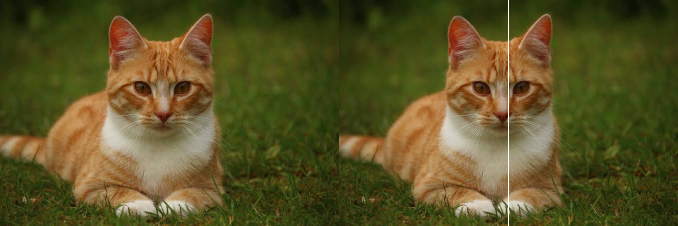

In [5]:
# Tugas 2: Garis Vertikal di Tengah

# Membuat copy dari gambar asli (image_2)
img_vertikal = cv.cvtColor(image, cv.COLOR_BGR2RGB)

# Loop pada sumbu Y (tinggi)
for y in range(tinggi):
    img_vertikal[y, int(lebar/2)] = [255, 255, 255]

final_frame_2a = cv.hconcat((image_2, img_vertikal))
cv2_imshow(final_frame_2a)

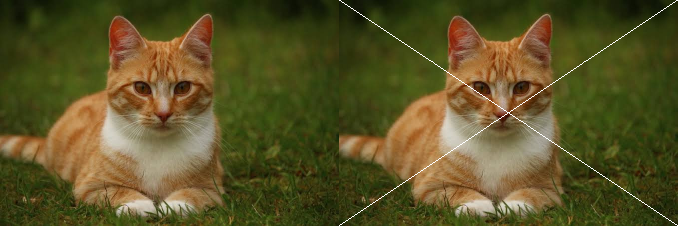

In [6]:
#Tugas 2: Garis Menyilang (Diagonal)

img_diagonal = cv.cvtColor(image, cv.COLOR_BGR2RGB)

for x in range(lebar):
    # Garis diagonal 1 (Kiri Atas ke Kanan Bawah)
    y1 = int((x / lebar) * tinggi)
    if y1 < tinggi:
        img_diagonal[y1, x] = [255, 255, 255]

    # Garis diagonal 2 (Kanan Atas ke Kiri Bawah)
    y2 = int(((lebar - 1 - x) / lebar) * tinggi)
    if y2 < tinggi:
        img_diagonal[y2, x] = [255, 255, 255]

final_frame_2b = cv.hconcat((image_2, img_diagonal))
cv2_imshow(final_frame_2b)

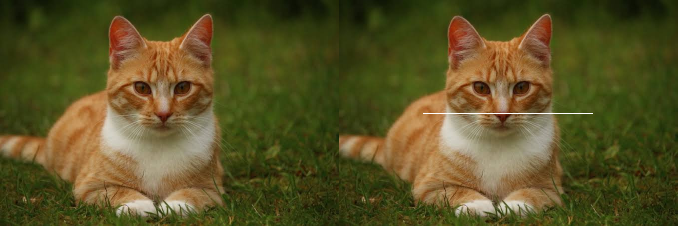

In [7]:
#Tugas 3: Garis Horizontal Berwarna Putih dengan Panjang Tertentu

img_horiz_pendek = cv.cvtColor(image, cv.COLOR_BGR2RGB)

titik_y = int(tinggi / 2)
batas_x_awal = int(lebar / 4)      # Mulai dari 25% lebar gambar
batas_x_akhir = int(lebar * 3/4)   # Berakhir di 75% lebar gambar

# Loop sumbu x hanya pada rentang tertentu
for x in range(batas_x_awal, batas_x_akhir):
    img_horiz_pendek[titik_y, x] = [255, 255, 255]

final_frame_3 = cv.hconcat((image_2, img_horiz_pendek))
cv2_imshow(final_frame_3)

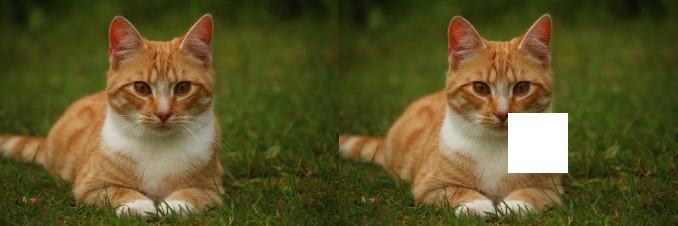

In [8]:
#Tugas 4: Membuat Kotak Putih

img_kotak = cv.cvtColor(image, cv.COLOR_BGR2RGB)

# Tentukan posisi dan ukuran kotak (misal: 60x60 pixel)
y_awal = int(tinggi / 2)
y_akhir = y_awal + 60
x_awal = int(lebar / 2)
x_akhir = x_awal + 60

# Nested loop untuk mewarnai area di dalam rentang tersebut
for y in range(y_awal, y_akhir):
    for x in range(x_awal, x_akhir):
        # Validasi batas agar tidak out of bounds jika gambar terlalu kecil
        if y < tinggi and x < lebar:
            img_kotak[y, x] = [255, 255, 255]

final_frame_4 = cv.hconcat((image_2, img_kotak))
cv2_imshow(final_frame_4)